当前工作目录： C:\Users\zjy21\anaconda jupyter notebook\exp3
图像 a 的尺寸： (1080, 1044, 3)
图像 b 的尺寸： (1080, 1413, 3)


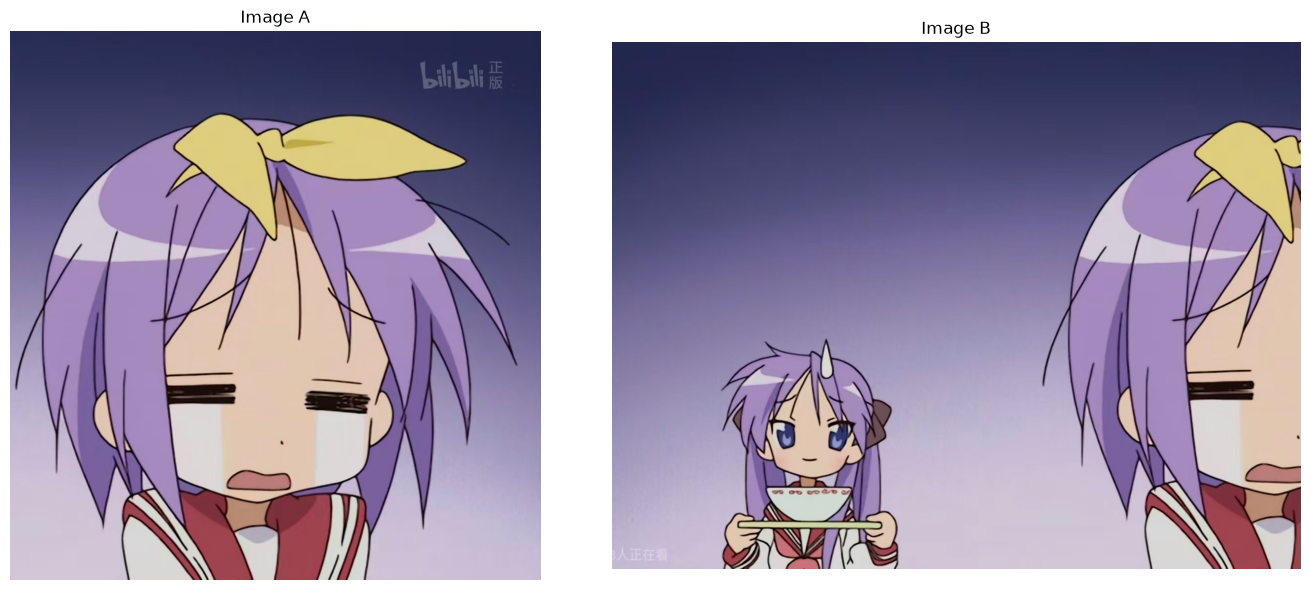

In [10]:
from pathlib import Path
import matplotlib.pyplot as plt

print("当前工作目录：", Path.cwd())

if img_a is None or img_b is None:
    raise FileNotFoundError("图片读取失败，请检查工作目录和文件名")

print("图像 a 的尺寸：", img_a.shape)
print("图像 b 的尺寸：", img_b.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(axes, [img_a, img_b], ["Image A", "Image B"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

图像 A 的关键点数量： 847
图像 B 的关键点数量： 1151
A 的描述符形状： (847, 128)
B 的描述符形状： (1151, 128)


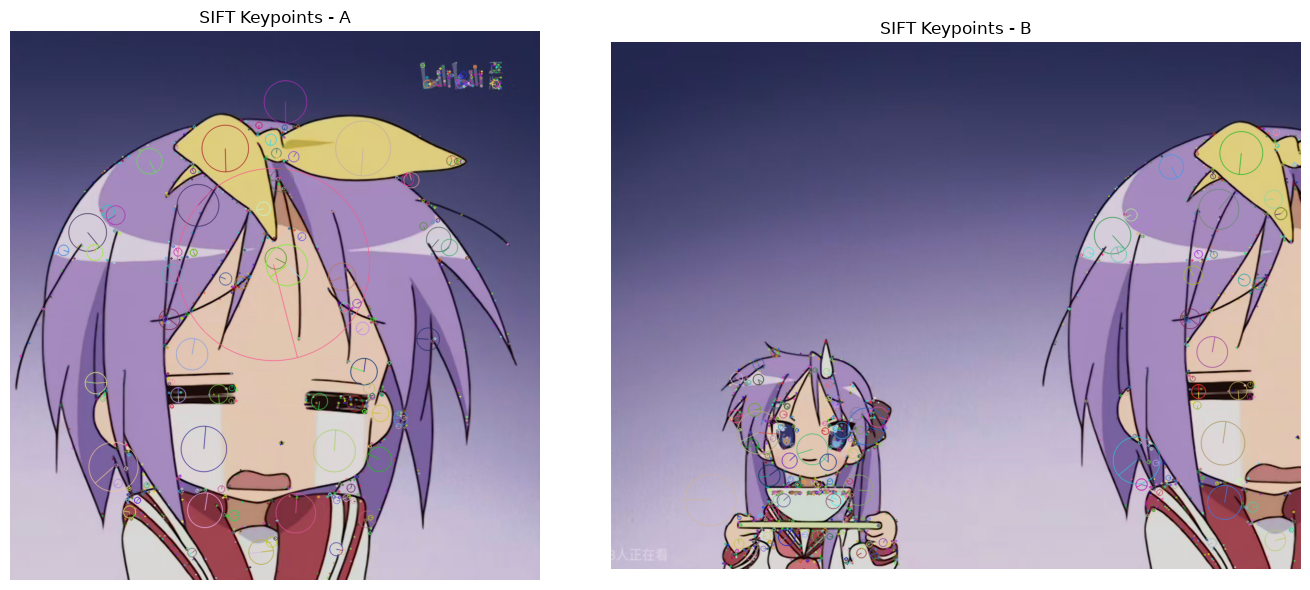

In [11]:
# 转为灰度图，用于检测特征
gray_a = cv2.cvtColor(img_a, cv2.COLOR_BGR2GRAY)
gray_b = cv2.cvtColor(img_b, cv2.COLOR_BGR2GRAY)

# 检测关键点并计算描述符
sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(gray_a, None)
kp_b, des_b = sift.detectAndCompute(gray_b, None)

print("图像 A 的关键点数量：", len(kp_a))
print("图像 B 的关键点数量：", len(kp_b))
print("A 的描述符形状：", None if des_a is None else des_a.shape)
print("B 的描述符形状：", None if des_b is None else des_b.shape)

# 在原图上画出关键点
keypoints_a = cv2.drawKeypoints(
    img_a, kp_a, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
keypoints_b = cv2.drawKeypoints(
    img_b, kp_b, None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(
    axes,
    [keypoints_a, keypoints_b],
    ["SIFT Keypoints - A", "SIFT Keypoints - B"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

初始匹配组数： 847
筛选后匹配数量： 368
保留比例：43.45%


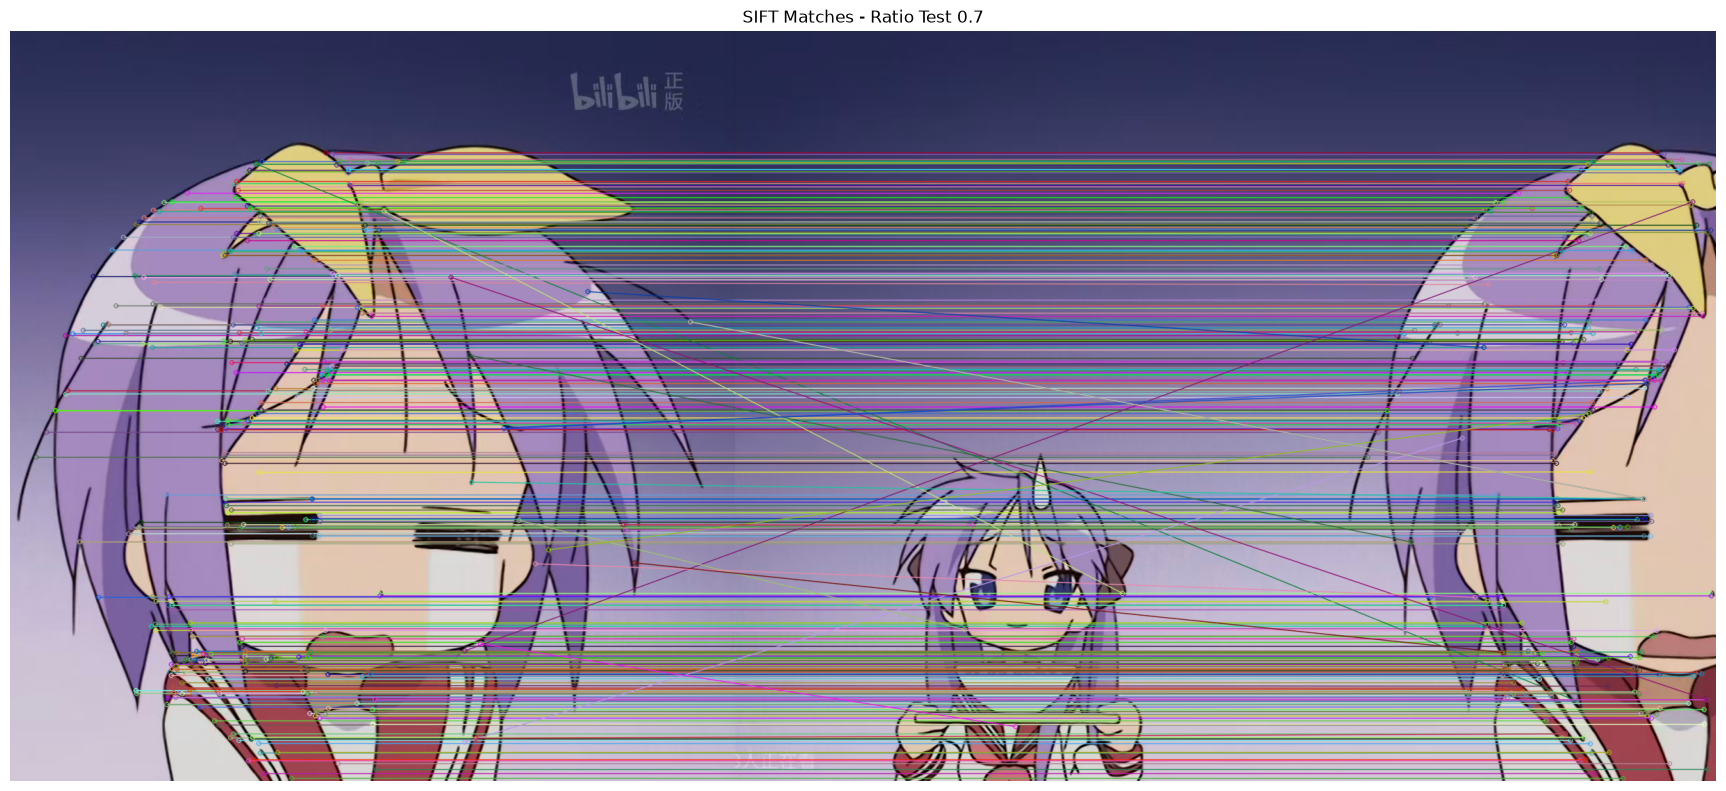

In [12]:
# 1. 创建 FLANN 匹配器
index_params = dict(algorithm=1, trees=5)
search_params = dict(checks=50)
flann = cv2.FlannBasedMatcher(index_params, search_params)

if des_a is None or des_b is None or len(des_b) < 2:
    raise ValueError("描述符不足，无法进行匹配")

# 2. 为 A 中的每个描述符，在 B 中寻找两个最接近的候选
matches = flann.knnMatch(des_a, des_b, k=2)

# 3. 比率测试：第一候选要明显优于第二候选，才保留
good_matches = []

for pair in matches:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.7 * n.distance:
            good_matches.append(m)

print("初始匹配组数：", len(matches))
print("筛选后匹配数量：", len(good_matches))
if matches:
    print(f"保留比例：{len(good_matches) / len(matches):.2%}")

# 4. 绘制筛选后的匹配连线
matched_keypoints_img = cv2.drawMatches(
    img_a, kp_a,
    img_b, kp_b,
    good_matches, None,
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(matched_keypoints_img, cv2.COLOR_BGR2RGB))
plt.title("SIFT Matches - Ratio Test 0.7")
plt.axis("off")
plt.tight_layout()
plt.show()

参与估计的匹配数量： 368
RANSAC 内点数量： 345
内点比例：93.75%
单应矩阵 H（B → A）：
 [[ 1.00127520e+00  2.43051764e-04 -8.74402696e+02]
 [ 2.88271033e-04  1.00123262e+00 -4.99417523e-01]
 [ 5.53357464e-07  4.28705668e-07  1.00000000e+00]]


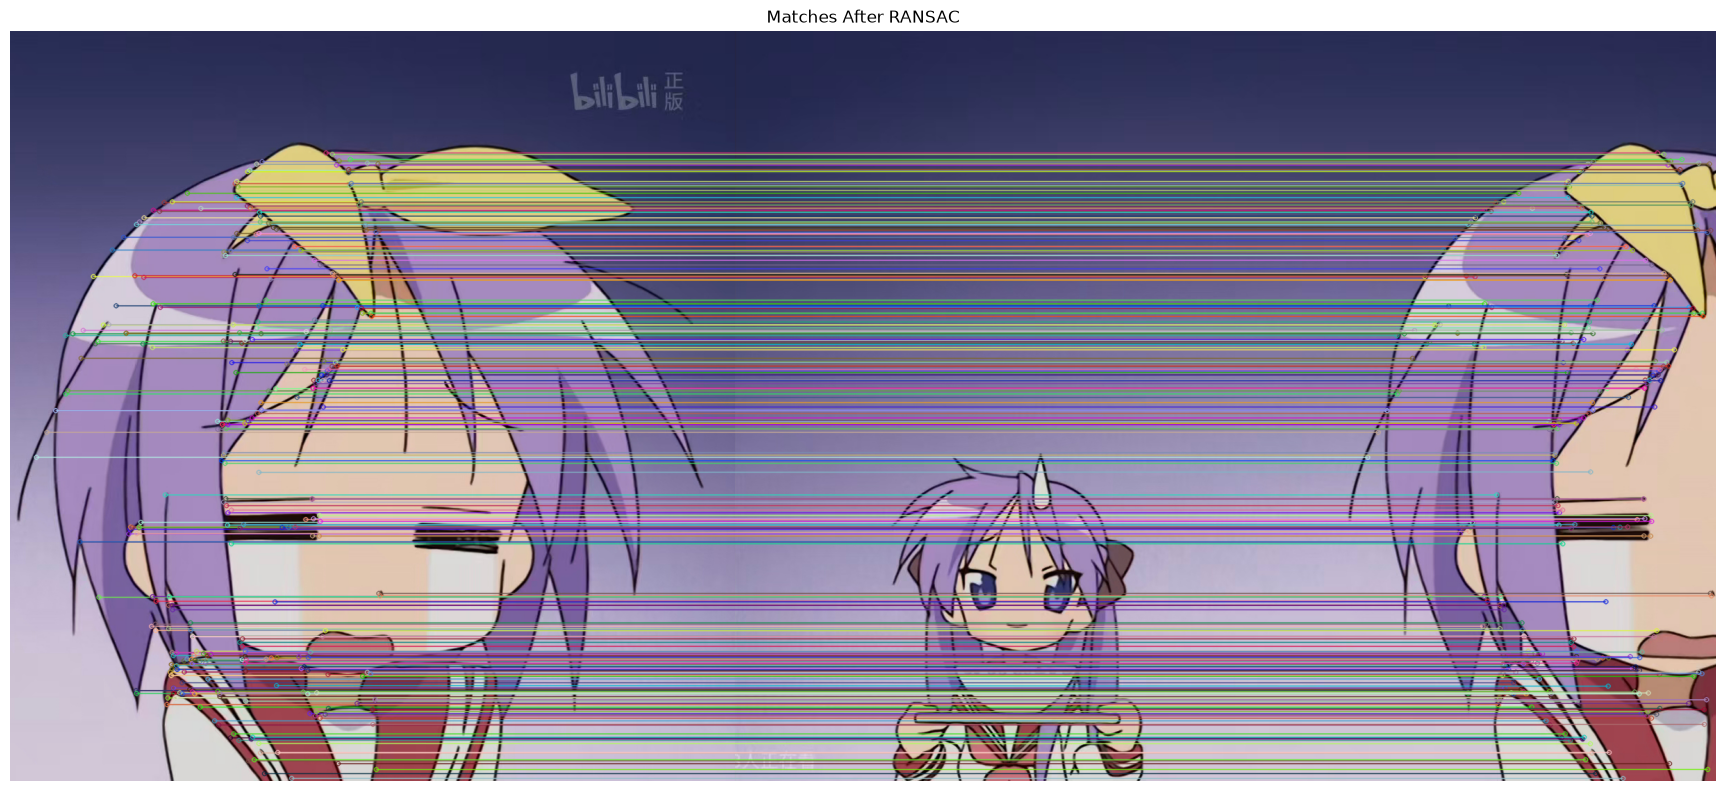

In [13]:
# 至少需要 4 对匹配点，且点的位置不能退化为共线等情况
if len(good_matches) < 4:
    raise ValueError("匹配点不足，无法估计单应矩阵")

# 将图像 B 变换到图像 A 的坐标系
src_pts = np.float32([
    kp_b[m.trainIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

dst_pts = np.float32([
    kp_a[m.queryIdx].pt for m in good_matches
]).reshape(-1, 1, 2)

# RANSAC：允许的重投影误差阈值为 5 像素
H, mask = cv2.findHomography(
    src_pts, dst_pts, cv2.RANSAC, 5.0
)

if H is None or mask is None or not np.isfinite(H).all():
    raise ValueError("未能得到有效的单应矩阵")

inlier_mask = mask.ravel().astype(bool)
inlier_count = int(inlier_mask.sum())

print("参与估计的匹配数量：", len(good_matches))
print("RANSAC 内点数量：", inlier_count)
print(f"内点比例：{inlier_count / len(good_matches):.2%}")
print("单应矩阵 H（B → A）：\n", H)

# 只绘制 RANSAC 判定的内点匹配
inlier_matches_img = cv2.drawMatches(
    img_a, kp_a, img_b, kp_b,
    good_matches, None,
    matchesMask=inlier_mask.astype(int).tolist(),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)

plt.figure(figsize=(18, 8))
plt.imshow(cv2.cvtColor(inlier_matches_img, cv2.COLOR_BGR2RGB))
plt.title("Matches After RANSAC")
plt.axis("off")
plt.tight_layout()
plt.show()

拼接结果尺寸（高、宽、通道）： (1082, 1919, 3)


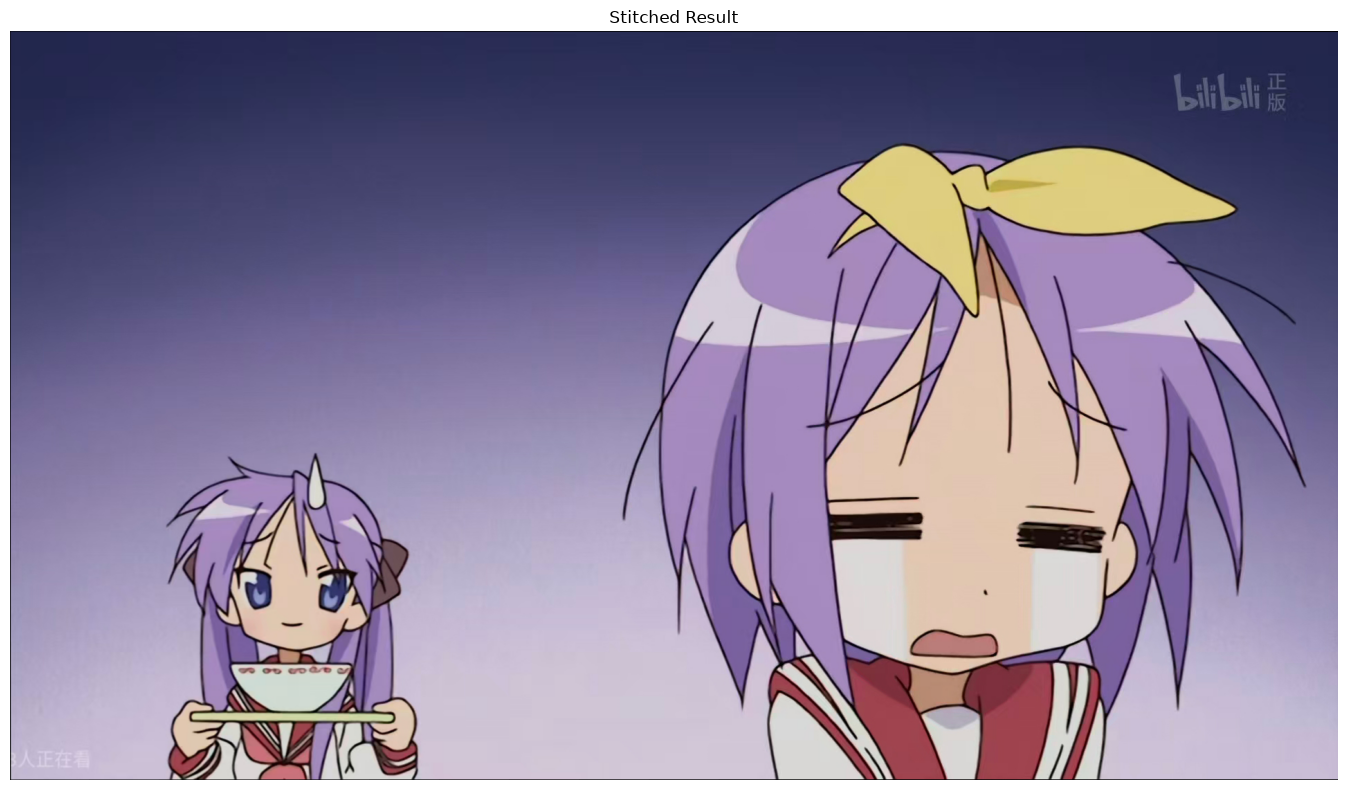

In [15]:
# 1. 获取两张图片的边界坐标
h_a, w_a = img_a.shape[:2]
h_b, w_b = img_b.shape[:2]

corners_a = np.float32([
    [0, 0], [w_a, 0], [w_a, h_a], [0, h_a]
]).reshape(-1, 1, 2)

corners_b = np.float32([
    [0, 0], [w_b, 0], [w_b, h_b], [0, h_b]
]).reshape(-1, 1, 2)

# 2. 计算 B 变换到 A 的坐标系后的边界
warped_corners_b = cv2.perspectiveTransform(corners_b, H)
all_corners = np.concatenate([corners_a, warped_corners_b])

if not np.isfinite(all_corners).all():
    raise ValueError("变换后的边界无效，请检查单应矩阵")

x_min, y_min = np.floor(
    all_corners.min(axis=0).ravel()
).astype(int)

x_max, y_max = np.ceil(
    all_corners.max(axis=0).ravel()
).astype(int)

canvas_w = int(x_max - x_min)
canvas_h = int(y_max - y_min)

# 避免错误变换产生过大的画布
if canvas_w <= 0 or canvas_h <= 0 or canvas_w * canvas_h > 30_000_000:
    raise ValueError("画布尺寸异常，请检查匹配与变换结果")

# 3. 平移到非负坐标，避免图像被画布裁掉
translation_matrix = np.array([
    [1, 0, -x_min],
    [0, 1, -y_min],
    [0, 0, 1]
], dtype=np.float64)

# 4. 将 B 放到新画布上
stitched_img = cv2.warpPerspective(
    img_b,
    translation_matrix @ H,
    (canvas_w, canvas_h)
)

# 5. 将 A 放到对应位置，覆盖重叠区域
offset_x = int(-x_min)
offset_y = int(-y_min)

stitched_img[
    offset_y:offset_y + h_a,
    offset_x:offset_x + w_a
] = img_a

print("拼接结果尺寸（高、宽、通道）：", stitched_img.shape)

plt.figure(figsize=(16, 8))
plt.imshow(cv2.cvtColor(stitched_img, cv2.COLOR_BGR2RGB))
plt.title("Stitched Result")
plt.axis("off")
plt.tight_layout()
plt.show()

In [16]:
from pathlib import Path
from datetime import datetime

# 每次保存到新文件夹，避免覆盖已有成果
result_dir = (
    Path.cwd() / "result"
    / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
)
result_dir.mkdir(parents=True, exist_ok=False)

images = {
    "gray_a.png": gray_a,
    "gray_b.png": gray_b,
    "keypoints_a.png": keypoints_a,
    "keypoints_b.png": keypoints_b,
    "matches_ratio.png": matched_keypoints_img,
    "matches_ransac.png": inlier_matches_img,
    "stitched_result.png": stitched_img,
}

# imencode + tofile 可处理含中文的文件路径
for name, image in images.items():
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise RuntimeError(f"图片编码失败：{name}")
    encoded.tofile(str(result_dir / name))

np.save(result_dir / "homography.npy", H)

print("已保存到：", result_dir)
print("保存的图片数量：", len(images))

已保存到： C:\Users\zjy21\anaconda jupyter notebook\exp3\result\20261022-141430-946874
保存的图片数量： 7


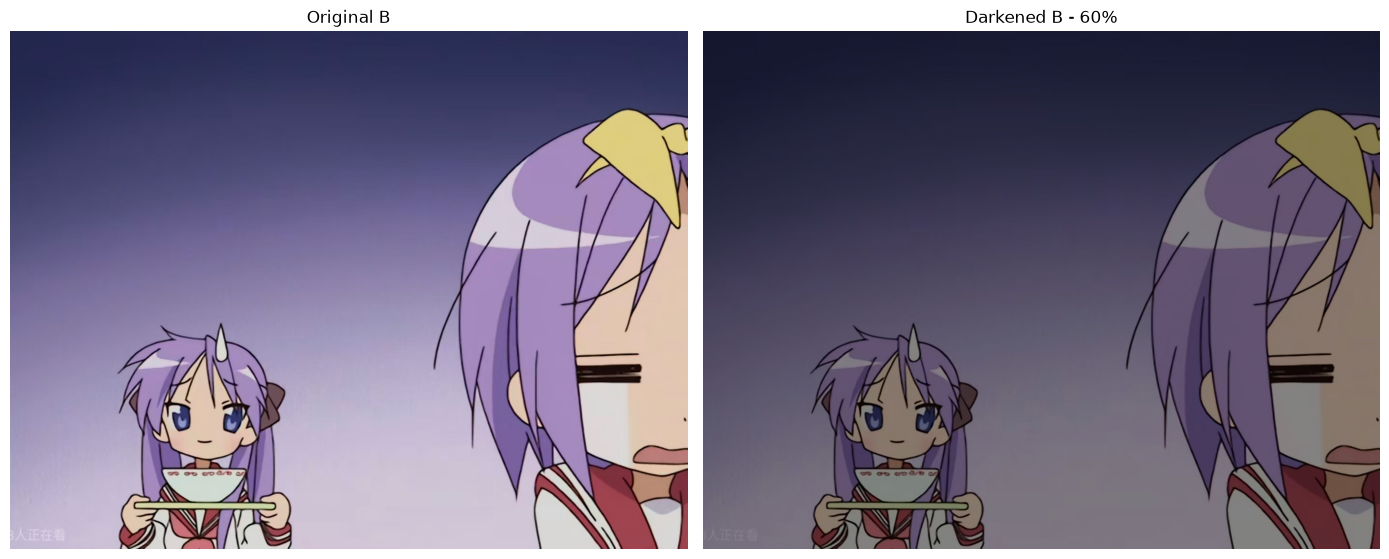

原始 B 的关键点数量： 1151
调暗 B 的关键点数量： 950


In [17]:
# 用浮点数计算，再转回 uint8，避免整数运算溢出
img_b_dark = np.clip(
    img_b.astype(np.float32) * 0.6, 0, 255
).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, img, title in zip(
    axes,
    [img_b, img_b_dark],
    ["Original B", "Darkened B - 60%"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# 在调暗后的 B 上重新提取特征
gray_b_dark = cv2.cvtColor(img_b_dark, cv2.COLOR_BGR2GRAY)
kp_b_dark, des_b_dark = sift.detectAndCompute(gray_b_dark, None)

print("原始 B 的关键点数量：", len(kp_b))
print("调暗 B 的关键点数量：", len(kp_b_dark))

调暗后筛选匹配数量： 289
调暗后 RANSAC 内点数量： 269
内点比例：93.08%


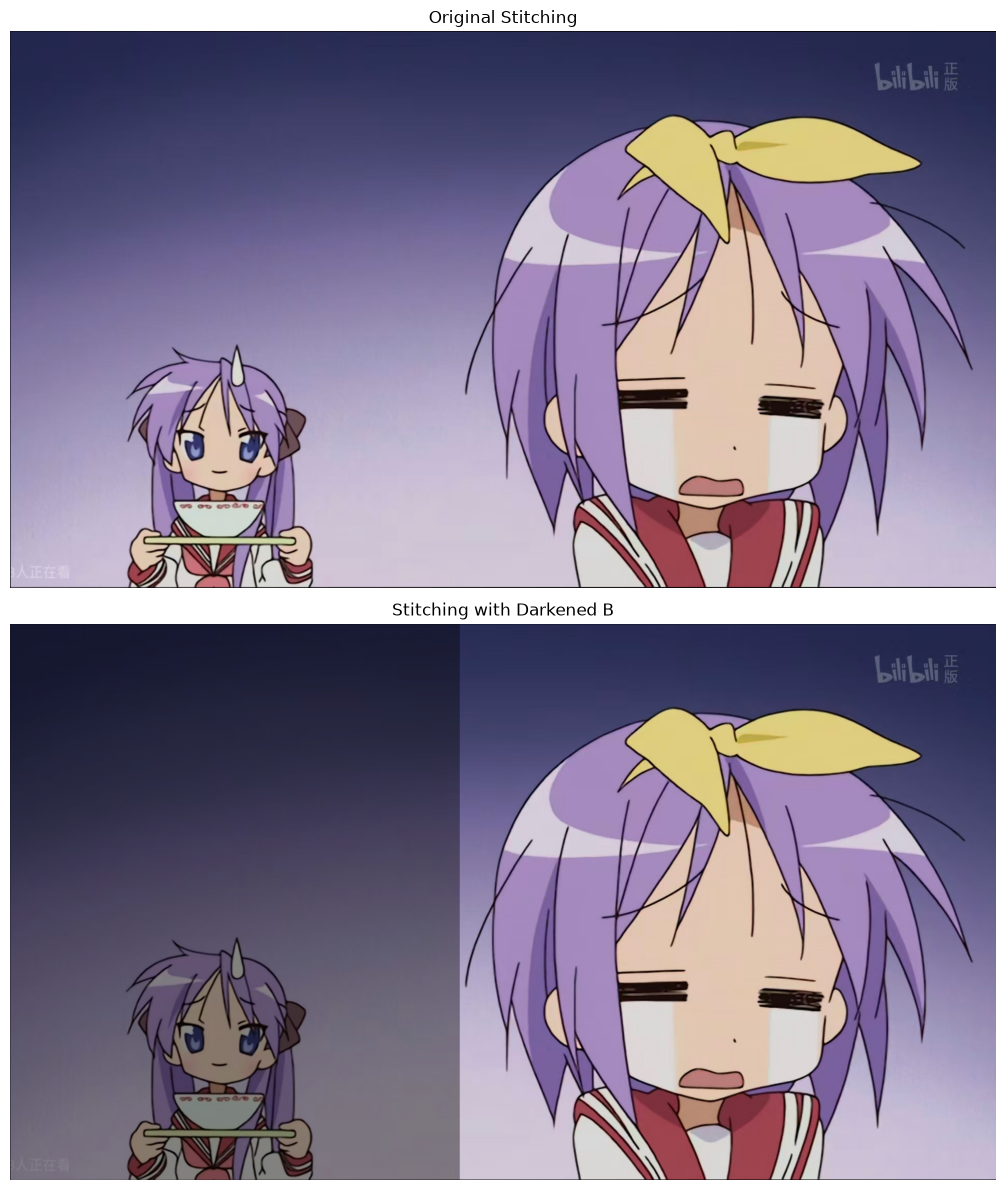

In [18]:
# 1. 重新匹配：A 不变，B 使用调暗后的描述符
if des_b_dark is None or len(des_b_dark) < 2:
    raise ValueError("调暗后的 B 特征不足")

matches_dark = flann.knnMatch(des_a, des_b_dark, k=2)

good_dark = []
for pair in matches_dark:
    if len(pair) == 2:
        m, n = pair
        if m.distance < 0.7 * n.distance:
            good_dark.append(m)

if len(good_dark) < 4:
    raise ValueError("筛选后匹配不足 4 对，无法估计变换")

# 2. 重新估计 B → A 的单应矩阵
src_dark = np.float32([
    kp_b_dark[m.trainIdx].pt for m in good_dark
]).reshape(-1, 1, 2)

dst_dark = np.float32([
    kp_a[m.queryIdx].pt for m in good_dark
]).reshape(-1, 1, 2)

H_dark, mask_dark = cv2.findHomography(
    src_dark, dst_dark, cv2.RANSAC, 5.0
)

if H_dark is None or mask_dark is None:
    raise ValueError("单应矩阵估计失败")

if not np.isfinite(H_dark).all() or mask_dark.sum() < 4:
    raise ValueError("变换矩阵或内点数量异常")

print("调暗后筛选匹配数量：", len(good_dark))
print("调暗后 RANSAC 内点数量：", int(mask_dark.sum()))
print(f"内点比例：{mask_dark.sum() / len(good_dark):.2%}")

# 3. 根据新矩阵计算画布范围
warped_corners_dark = cv2.perspectiveTransform(corners_b, H_dark)
all_corners_dark = np.concatenate([
    corners_a, warped_corners_dark
])

if not np.isfinite(all_corners_dark).all():
    raise ValueError("变换后的边界异常")

xmin_d, ymin_d = np.floor(
    all_corners_dark.min(axis=0).ravel()
).astype(int)

xmax_d, ymax_d = np.ceil(
    all_corners_dark.max(axis=0).ravel()
).astype(int)

width_d = int(xmax_d - xmin_d)
height_d = int(ymax_d - ymin_d)

if width_d <= 0 or height_d <= 0 or width_d * height_d > 30_000_000:
    raise ValueError("画布尺寸异常")

T_dark = np.array([
    [1, 0, -xmin_d],
    [0, 1, -ymin_d],
    [0, 0, 1]
], dtype=np.float64)

# 4. 变换调暗后的 B，再用原亮度 A 覆盖对应区域
stitched_dark = cv2.warpPerspective(
    img_b_dark, T_dark @ H_dark, (width_d, height_d)
)

ox_d, oy_d = int(-xmin_d), int(-ymin_d)
stitched_dark[
    oy_d:oy_d + h_a,
    ox_d:ox_d + w_a
] = img_a

# 5. 与正常亮度拼接结果对比
fig, axes = plt.subplots(2, 1, figsize=(16, 12))

for ax, img, title in zip(
    axes,
    [stitched_img, stitched_dark],
    ["Original Stitching", "Stitching with Darkened B"]
):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [19]:
# 使用前面创建的 result_dir
dark_result_dir = result_dir / (
    "brightness_" + datetime.now().strftime("%H%M%S-%f")
)
dark_result_dir.mkdir(parents=True, exist_ok=False)

for name, image in {
    "b_dark.png": img_b_dark,
    "stitched_dark.png": stitched_dark,
}.items():
    ok, encoded = cv2.imencode(".png", image)
    if not ok:
        raise RuntimeError(f"图片编码失败：{name}")
    encoded.tofile(str(dark_result_dir / name))

print("已保存到：", dark_result_dir)

已保存到： C:\Users\zjy21\anaconda jupyter notebook\exp3\result\20261022-141430-946874\brightness_142957-806967
